# 02 — Phân phối dữ liệu (Distributions)

**Mục tiêu:** mô tả hình dạng phân phối của các biến chính (giá, số lượng, doanh thu, thời gian
giao hàng/thanh toán, biên lợi nhuận, vòng quay), phát hiện lệch phải và ngoại lai, và xem
phân phối theo thời gian.

**Nguồn dữ liệu (đều đã tổng hợp sẵn trong `analytics.db`):**

| Truy vấn | Bảng | Dùng cho |
|---|---|---|
| `sample_sales` | mẫu hệ thống 1/50 của `sales` | phân phối cấp giao dịch bán |
| `sample_purchases` | mẫu hệ thống 1/10 của `purchases` | phân phối cấp dòng mua |
| `products` | `dim_product` | giá niêm yết, dung tích, nhóm |
| `po_metrics` | `mart_po` | lead time, thời gian thanh toán, phí vận chuyển |
| `vendor_brand` | `mart_vendor_brand` | biên, vòng quay theo sản phẩm |
| `sales_daily`, `sales_weekday` | `mart_sales_daily` | phân phối theo thời gian |

## 0. Thiết lập môi trường
Thêm thư mục gốc dự án vào `sys.path` để import package `src`, nạp thư viện và áp dụng
phong cách biểu đồ xuất bản (bảng màu **đậm**) dùng chung cho mọi notebook.

In [1]:
%matplotlib inline
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import data_loader as dl, preprocessing as pp, visualization as viz
from src.config import TABLE_DIR
from src.visualization import PALETTE, CLASS_COLORS

viz.set_style()
TABLE_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.2f}".format)

## 1. Nạp dữ liệu
Mỗi lệnh `dl.query` chỉ đọc 1 bảng nhỏ (< 300 nghìn dòng) nên cả cell chạy trong vài giây.
Ép kiểu ngày bằng `pp.parse_dates` và thêm tên nhóm sản phẩm.

In [2]:
sales = pp.add_class_name(dl.query("sample_sales"))
purch = pp.add_class_name(dl.query("sample_purchases"))
prod = dl.query("products")
po = pp.parse_dates(dl.query("po_metrics"), ["PODate", "FirstReceivingDate", "InvoiceDate", "PayDate"])
vb = dl.query("vendor_brand")
daily = pp.parse_dates(dl.query("sales_daily"), ["SalesDate"])
{k: len(v) for k, v in dict(sales=sales, purch=purch, prod=prod, po=po, vb=vb, daily=daily).items()}

{'sales': 256507,
 'purch': 237247,
 'prod': 12261,
 'po': 5543,
 'vb': 11450,
 'daily': 364}

## 2. Thống kê mô tả mở rộng

Bảng mô tả cho biến cấp giao dịch bán: phân vị 1–99 %, độ lệch (skew), độ nhọn (kurtosis).
Skew ≫ 1 ⇒ phân phối lệch phải mạnh → nên vẽ trên thang log.

In [3]:
sales_cols = ["SalesQuantity", "SalesPrice", "SalesDollars", "Volume", "ExciseTax", "excise_per_liter"]
desc_sales = pp.describe_distribution(sales, sales_cols)
desc_sales.to_csv(TABLE_DIR / "02_describe_sales.csv")
desc_sales

,n,mean,std,min,p1,p5,p25,median,p75,p95,p99,max,skew,kurtosis,zero_pct
SalesQuantity,"256,507.00",2.55,4.36,1.00,1.00,1.00,1.00,1.00,2.00,8.00,18.00,479.00,17.08,902.64,0.00
SalesPrice,"256,507.00",15.73,17.03,0.49,0.99,0.99,8.99,12.99,18.99,37.99,62.99,"4,999.99",102.61,"28,787.75",0.00
SalesDollars,"256,507.00",35.22,84.52,0.49,0.99,3.98,10.99,18.99,34.99,107.96,274.95,"8,678.76",26.33,"1,391.99",0.00
Volume,"256,507.00",938.83,697.53,50.00,50.00,50.00,750.00,750.00,"1,000.00","1,750.00","5,000.00","18,000.00",2.77,17.85,0.00
ExciseTax,"256,507.00",1.48,4.55,0.01,0.05,0.10,0.21,0.75,1.57,5.51,15.75,349.12,21.10,830.03,0.00
excise_per_liter,"256,507.00",0.68,0.44,0.13,0.15,0.15,0.15,1.04,1.05,1.05,1.07,1.07,-0.35,-1.87,0.00


Tương tự cho dòng mua hàng và cấp đơn hàng (PO).

In [4]:
desc_purch = pd.concat([
    pp.describe_distribution(purch, ["PurchasePrice", "Quantity", "Dollars", "line_lead_days", "pay_days"]),
    pp.describe_distribution(po, ["n_lines", "line_dollars", "Freight", "freight_pct", "lead_days", "lead_days_first", "pay_days"])
      .rename(index=lambda c: f"PO.{c}"),
])
desc_purch.to_csv(TABLE_DIR / "02_describe_purchases.csv")
desc_purch

,n,mean,std,min,p1,p5,p25,median,p75,p95,p99,max,skew,kurtosis,zero_pct
PurchasePrice,"237,247.00",12.05,15.63,0.00,0.75,3.39,6.12,9.22,14.49,28.88,47.61,"2,661.86",65.75,"9,001.27",0.01
Quantity,"237,247.00",14.12,23.47,1.00,1.00,3.00,6.00,10.00,12.00,46.00,119.00,"1,793.00",12.43,451.78,0.00
Dollars,"237,247.00",135.80,292.00,0.00,9.26,23.82,49.20,83.76,141.12,376.74,955.14,"38,949.90",35.52,"2,898.52",0.01
line_lead_days,"237,247.00",7.62,2.21,3.00,3.00,4.00,6.00,8.00,9.00,11.00,12.00,14.00,0.00,-0.60,0.00
pay_days,"237,247.00",35.66,6.06,23.00,24.00,26.00,31.00,36.00,41.00,46.00,47.00,48.00,0.03,-0.93,0.00
PO.n_lines,"5,543.00",428.01,876.97,1.00,1.00,1.00,8.00,39.00,439.00,"2,397.00","4,208.74","6,108.00",3.02,9.57,0.00
PO.line_dollars,"5,543.00","58,073.38","140,234.03",4.14,44.03,127.32,967.81,"4,765.45","44,587.18","303,817.27","704,495.39","1,660,435.88",4.62,28.09,0.00
PO.Freight,"5,543.00",295.95,713.59,0.02,0.23,0.66,5.02,24.73,229.66,"1,542.38","3,634.19","8,468.22",4.66,28.82,0.00
PO.freight_pct,"5,543.00",0.55,0.48,0.44,0.45,0.45,0.47,0.50,0.53,0.55,2.72,11.52,13.21,218.87,0.00
PO.lead_days,"5,543.00",9.93,2.13,3.00,5.00,7.00,8.00,10.00,12.00,13.00,14.00,14.00,-0.13,-0.47,0.00


## 3. Phân phối cấp giao dịch bán (mẫu 1/50)

**Biểu đồ 2.1 — Giá bán, số lượng và doanh thu mỗi dòng bán.** Bin đều trên log10;
đường đứt đỏ đậm = trung vị. Panel 4 so sánh giá bán giữa 2 nhóm.

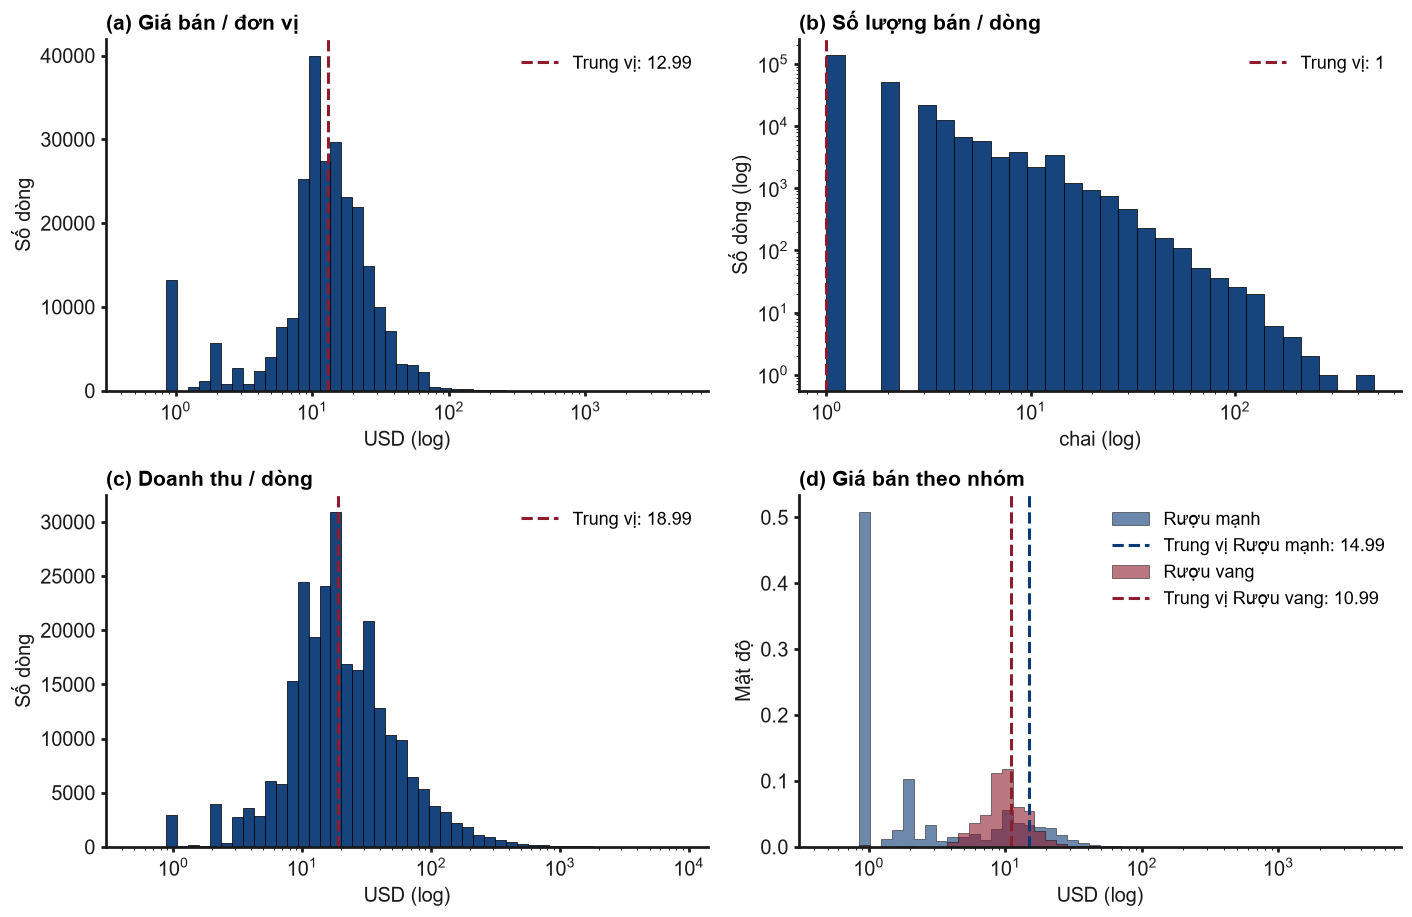

In [5]:
fig, axes = viz.new_figure(2, 2, figsize=(13, 8.5))
viz.hist(axes[0], sales["SalesPrice"], log_x=True, bins=50)
viz.label(axes[0], "(a) Giá bán / đơn vị", "USD (log)", "Số dòng")
viz.hist(axes[1], sales["SalesQuantity"], log_x=True, bins=30, log_y=True)
viz.label(axes[1], "(b) Số lượng bán / dòng", "chai (log)", "Số dòng (log)")
viz.hist(axes[2], sales["SalesDollars"], log_x=True, bins=50)
viz.label(axes[2], "(c) Doanh thu / dòng", "USD (log)", "Số dòng")
viz.hist(axes[3], {n: g["SalesPrice"] for n, g in sales.groupby("ClassName", observed=True)},
         log_x=True, bins=50, colors=[CLASS_COLORS[1], CLASS_COLORS[2]], density=True, alpha=0.6)
viz.label(axes[3], "(d) Giá bán theo nhóm", "USD (log)", "Mật độ")
viz.save_figure(fig, "02_sales_line_distributions")
plt.show()

**Biểu đồ 2.2 — Dung tích chai và thuế tiêu thụ.** Dung tích là biến rời rạc → vẽ cột tần suất
top 10; thuế/lít cho thấy mức thuế tách biệt rõ giữa rượu mạnh và rượu vang.

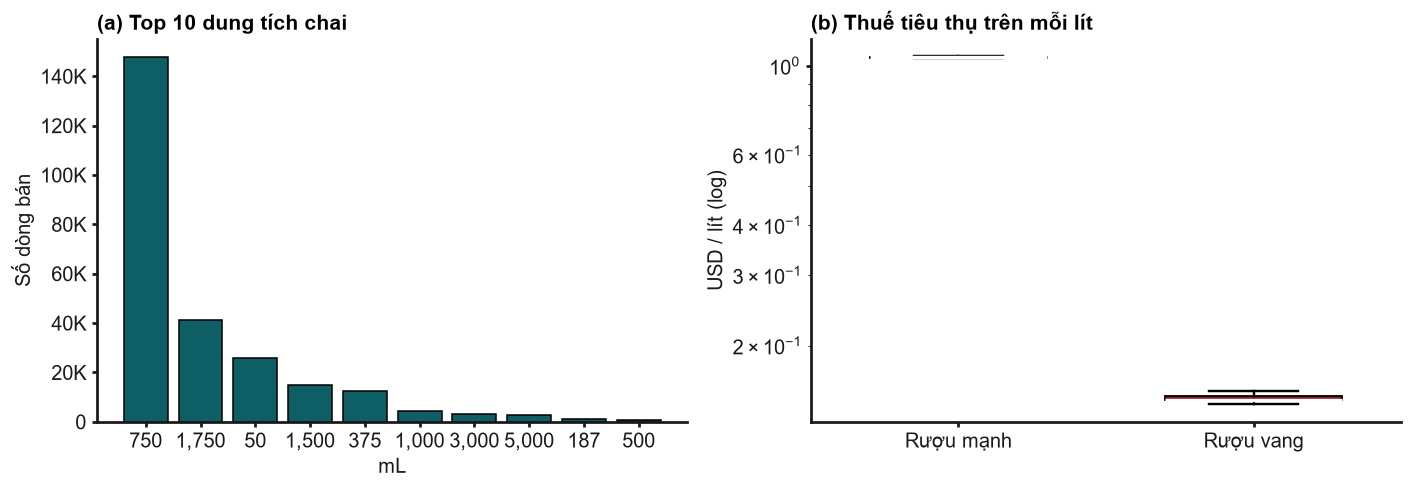

,count,mean,std,min,25%,50%,75%,max
ClassName,,,,,,,,
Rượu mạnh,"150,541.00",1.05,0.01,1.00,1.05,1.05,1.05,1.07
Rượu vang,"105,966.00",0.15,0.00,0.13,0.15,0.15,0.15,0.20


In [6]:
vol = sales["Volume"].value_counts().head(10)
fig, axes = viz.new_figure(1, 2, figsize=(13, 4.6))
viz.bar(axes[0], [f"{v:,.0f}" for v in vol.index], {"Số dòng": vol.values}, colors=[PALETTE["teal"]])
viz.fmt_axis(axes[0], y="count")
viz.label(axes[0], "(a) Top 10 dung tích chai", "mL", "Số dòng bán")
viz.boxplot(axes[1], {n: g["excise_per_liter"] for n, g in sales.groupby("ClassName", observed=True)},
            colors=[CLASS_COLORS[1], CLASS_COLORS[2]], log_y=True)
viz.label(axes[1], "(b) Thuế tiêu thụ trên mỗi lít", None, "USD / lít (log)")
viz.save_figure(fig, "02_volume_excise")
plt.show()
sales.groupby("ClassName", observed=True)["excise_per_liter"].describe()

## 4. Danh mục sản phẩm

**Biểu đồ 2.3 — Giá niêm yết, biên đơn vị và phân khúc giá** trên toàn bộ 12 261 sản phẩm
(`dim_product`). Biên đơn vị = (giá bán lẻ − giá mua) / giá bán lẻ.

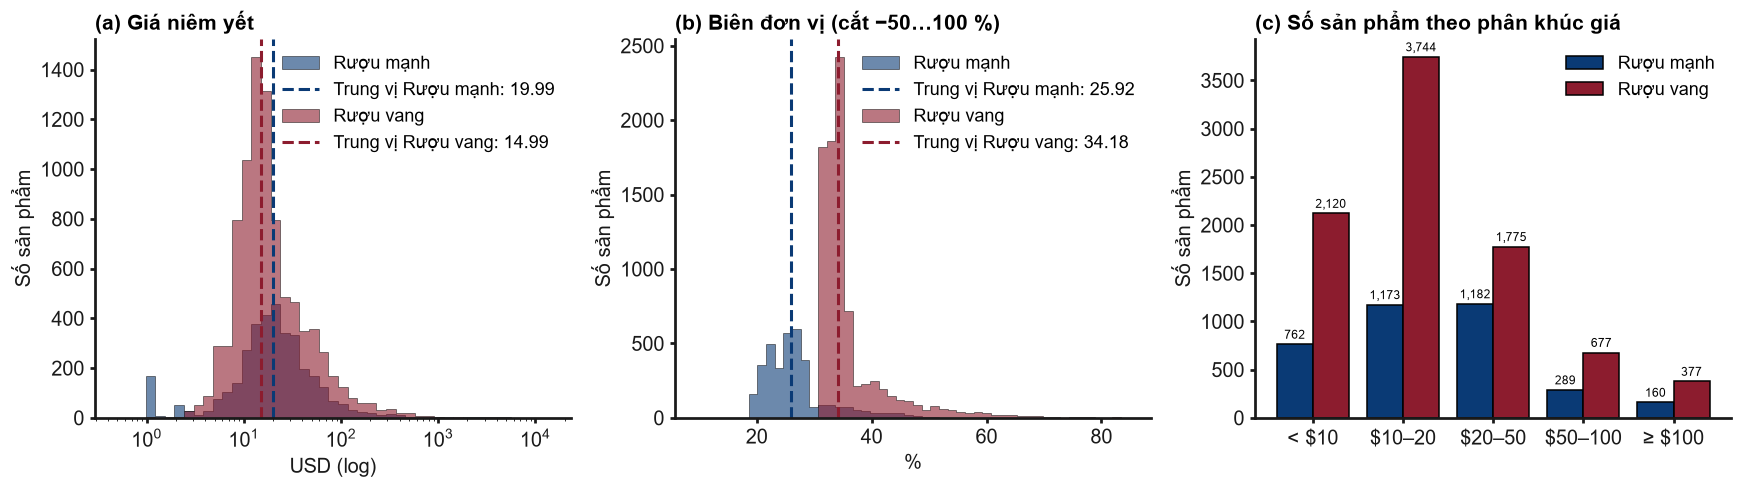

In [7]:
p = prod[prod["RetailPrice"] > 0]
fig, axes = viz.new_figure(1, 3, figsize=(16, 4.6))
viz.hist(axes[0], {n: g["RetailPrice"] for n, g in p.groupby("ClassName")}, log_x=True, bins=45,
         colors=[CLASS_COLORS[1], CLASS_COLORS[2]], alpha=0.6)
viz.label(axes[0], "(a) Giá niêm yết", "USD (log)", "Số sản phẩm")
viz.hist(axes[1], {n: g["UnitMarginPct"].clip(-50, 100) for n, g in p.groupby("ClassName")}, bins=50,
         colors=[CLASS_COLORS[1], CLASS_COLORS[2]], alpha=0.6)
viz.label(axes[1], "(b) Biên đơn vị (cắt −50…100 %)", "%", "Số sản phẩm")
band = p.groupby(["PriceBand", "ClassName"]).size().unstack(fill_value=0)
viz.bar(axes[2], [b[3:] for b in band.index], {c: band[c].values for c in band.columns},
        colors=[CLASS_COLORS[1], CLASS_COLORS[2]], annotate="{:,.0f}", fontsize=8)
viz.label(axes[2], "(c) Số sản phẩm theo phân khúc giá", None, "Số sản phẩm")
viz.save_figure(fig, "02_product_catalog")
plt.show()

Top 10 quy cách (`Size`) — thấy rõ định dạng không đồng nhất (`750mL`, `1.75L`, `Liter`, `… Pk`).

In [8]:
prod["Size"].value_counts().head(10).to_frame("n_products")

,n_products
Size,
750mL,9823
1500mL,486
1750mL,433
1000mL,427
375mL,318
50mL,276
3000mL,104
187mL,52
500mL,51


## 5. Mua hàng & đơn hàng

**Biểu đồ 2.4 — Giá mua, số lượng mỗi dòng mua và giá trị đơn hàng (PO).**

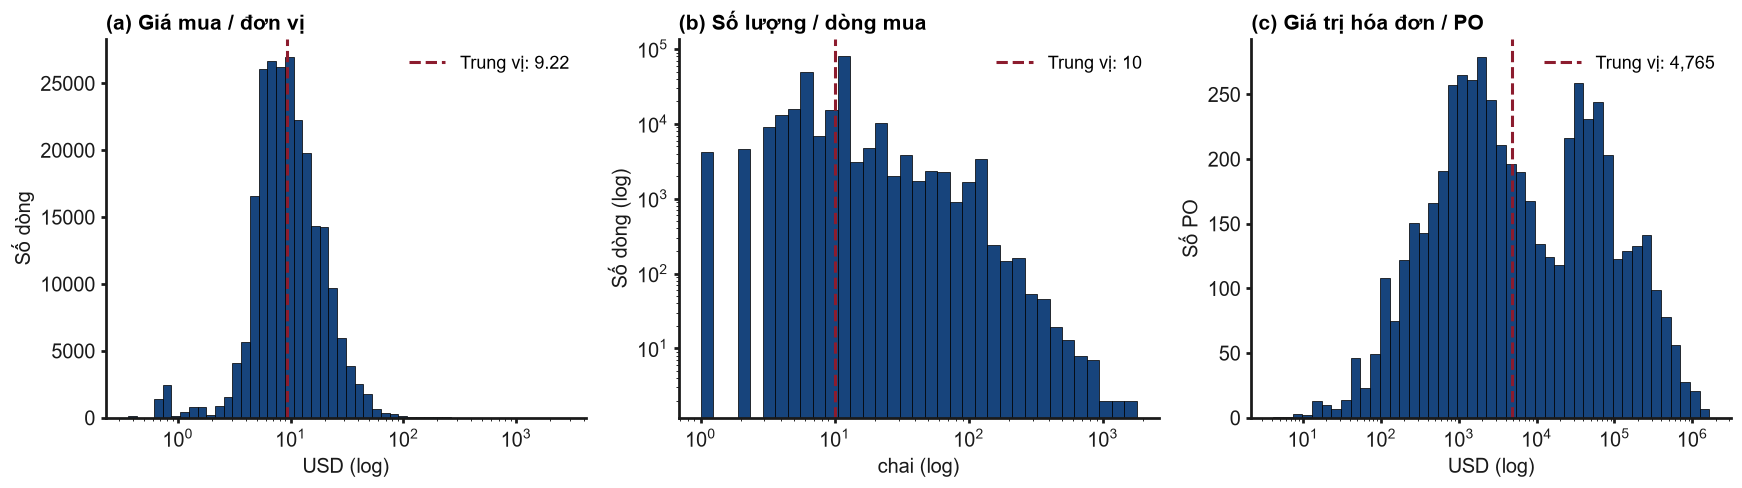

In [9]:
fig, axes = viz.new_figure(1, 3, figsize=(16, 4.6))
viz.hist(axes[0], pp.positive(purch["PurchasePrice"]), log_x=True, bins=50, )
viz.label(axes[0], "(a) Giá mua / đơn vị", "USD (log)", "Số dòng")
viz.hist(axes[1], purch["Quantity"], log_x=True, bins=35, log_y=True)
viz.label(axes[1], "(b) Số lượng / dòng mua", "chai (log)", "Số dòng (log)")
viz.hist(axes[2], po["invoice_dollars"], log_x=True, bins=45)
viz.label(axes[2], "(c) Giá trị hóa đơn / PO", "USD (log)", "Số PO")
viz.save_figure(fig, "02_purchase_distributions")
plt.show()

**Biểu đồ 2.5 — Lead time (đặt hàng → nhận đủ lô cuối của PO), thời gian thanh toán (hóa đơn → trả)
và tỷ lệ phí vận chuyển / tiền hàng** ở cấp PO. Hai biến thời gian là số ngày nguyên → cột tần suất.

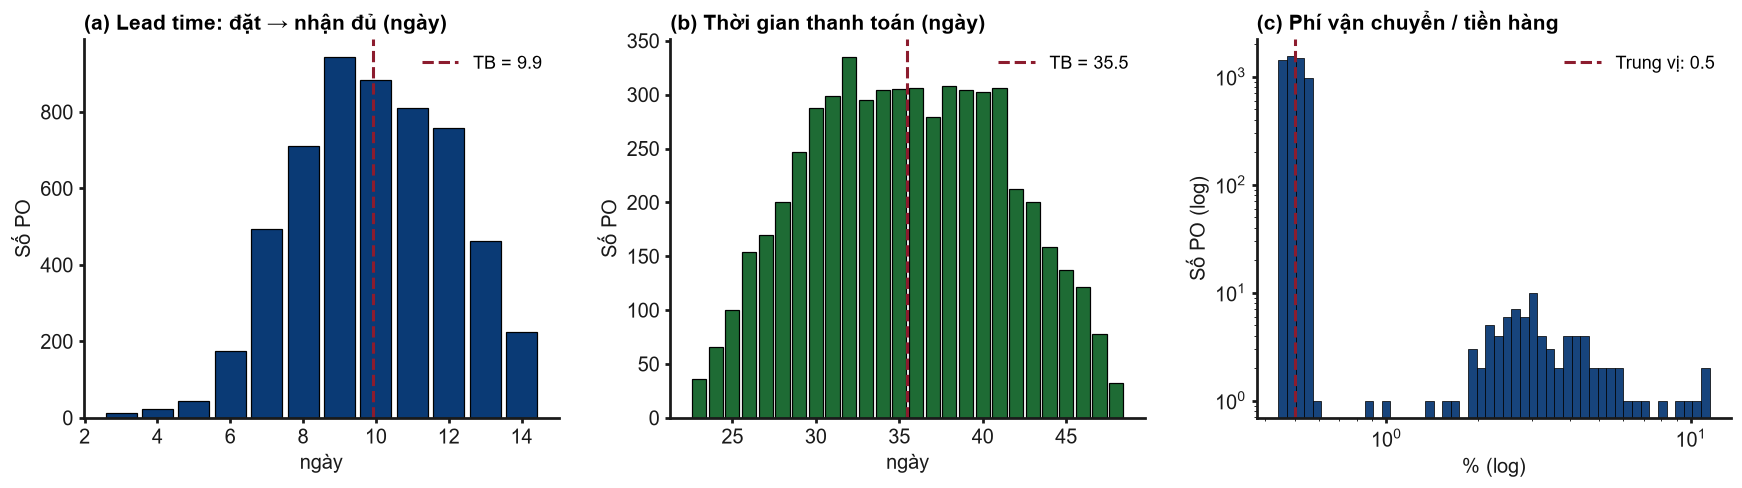

In [10]:
fig, axes = viz.new_figure(1, 3, figsize=(16, 4.6))
for ax, col, title, c in [(axes[0], "lead_days", "(a) Lead time: đặt → nhận đủ (ngày)", PALETTE["blue"]),
                          (axes[1], "pay_days", "(b) Thời gian thanh toán (ngày)", PALETTE["green"])]:
    vc = po[col].round().value_counts().sort_index()
    ax.bar(vc.index, vc.values, color=c, edgecolor="black", linewidth=0.8, width=0.85)
    ax.axvline(po[col].mean(), color=PALETTE["wine"], ls="--", lw=2, label=f"TB = {po[col].mean():.1f}")
    ax.legend()
    viz.label(ax, title, "ngày", "Số PO")
viz.hist(axes[2], po["freight_pct"], bins=50, log_x=True, log_y=True)
viz.label(axes[2], "(c) Phí vận chuyển / tiền hàng", "% (log)", "Số PO (log)")
viz.save_figure(fig, "02_po_time_freight")
plt.show()

## 6. Hiệu quả sản phẩm (NCC × Brand)

**Biểu đồ 2.6 — Biên lợi nhuận gộp, vòng quay hàng và doanh thu mỗi sản phẩm**
(`mart_vendor_brand`). Biên cắt ở [−100, 100] % để dễ đọc; sản phẩm không bán được (biên NULL) bị bỏ.
Đường dọc xám ở vòng quay = 1 (bán hết lượng đã mua).

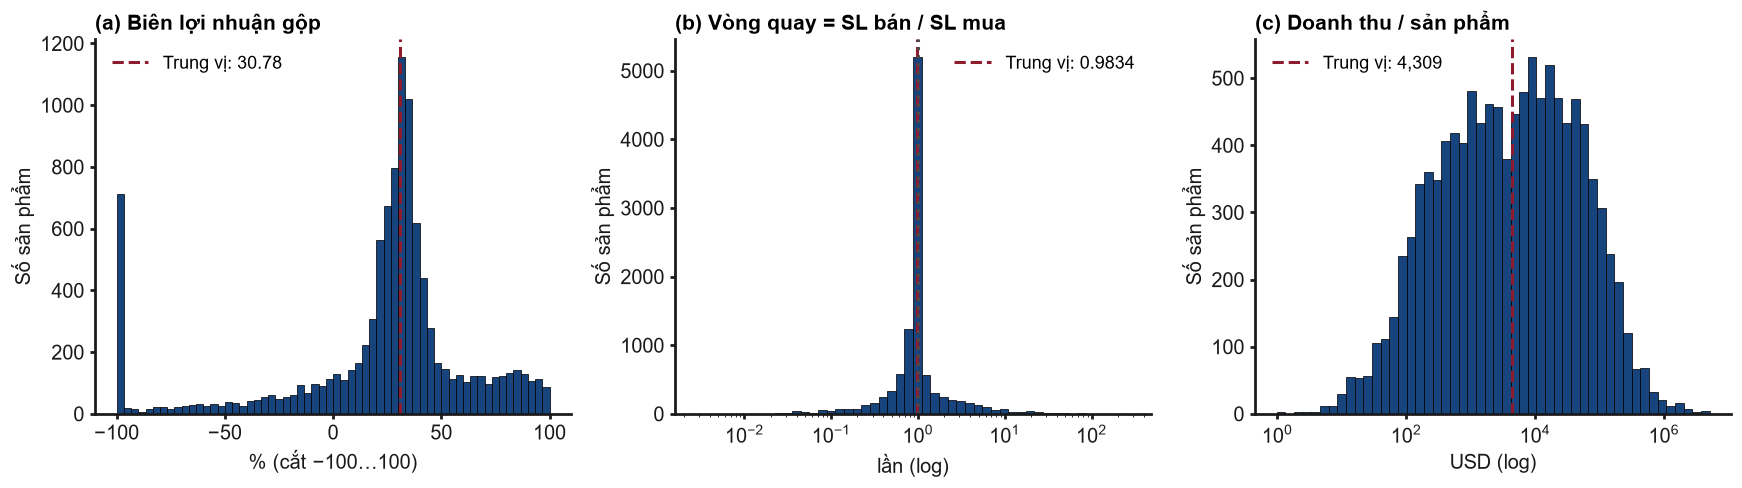

In [11]:
fig, axes = viz.new_figure(1, 3, figsize=(16, 4.6))
viz.hist(axes[0], vb["margin_pct"].clip(-100, 100), bins=60)
viz.label(axes[0], "(a) Biên lợi nhuận gộp", "% (cắt −100…100)", "Số sản phẩm")
viz.hist(axes[1], pp.positive(vb["stock_turnover"]), log_x=True, bins=50)
axes[1].axvline(1, color=PALETTE["gray"], lw=2, ls=":")
viz.label(axes[1], "(b) Vòng quay = SL bán / SL mua", "lần (log)", "Số sản phẩm")
viz.hist(axes[2], pp.positive(vb["sales_dollars"]), log_x=True, bins=50)
viz.label(axes[2], "(c) Doanh thu / sản phẩm", "USD (log)", "Số sản phẩm")
viz.save_figure(fig, "02_brand_kpi_distributions")
plt.show()

Đếm nhanh nhóm sản phẩm đặc biệt: lỗ gộp, không bán được, bán vượt lượng mua (vòng quay > 1).

In [12]:
pd.Series({
    "Tổng sản phẩm (NCC×Brand)": len(vb),
    "Không bán được (sales_qty = 0)": int((vb["sales_qty"] == 0).sum()),
    "Lỗ gộp (gross_profit < 0)": int((vb["gross_profit"] < 0).sum()),
    "Vòng quay < 0.5": int((vb["stock_turnover"] < 0.5).sum()),
    "Vòng quay > 1": int((vb["stock_turnover"] > 1).sum()),
}).to_frame("số lượng")

,số lượng
Tổng sản phẩm (NCC×Brand),11450
Không bán được (sales_qty = 0),178
Lỗ gộp (gross_profit < 0),2127
Vòng quay < 0.5,1280
Vòng quay > 1,3495


## 7. Ngoại lai

Đếm ngoại lai theo quy tắc IQR (k = 1,5) **trên thang log10** — phù hợp với biến lệch phải
(trên thang tuyến tính hầu như mọi giá trị lớn đều bị coi là ngoại lai).

In [13]:
out = pd.concat([
    pp.outlier_summary(sales, ["SalesPrice", "SalesQuantity", "SalesDollars"], log=True).rename(index=lambda c: f"sales.{c}"),
    pp.outlier_summary(purch, ["PurchasePrice", "Quantity", "Dollars"], log=True).rename(index=lambda c: f"purchases.{c}"),
    pp.outlier_summary(po, ["invoice_dollars", "Freight"], log=True).rename(index=lambda c: f"po.{c}"),
])
out.to_csv(TABLE_DIR / "02_outliers_log_iqr.csv")
out

,n,lower,upper,n_low,n_high,outlier_pct
sales.SalesPrice,"256,507.00",2.93,58.30,"21,675.00","3,644.00",9.87
sales.SalesQuantity,"256,507.00",0.35,5.66,0.00,"22,485.00",8.77
sales.SalesDollars,"256,507.00",1.93,198.78,"3,292.00","4,554.00",3.06
purchases.PurchasePrice,"237,224.00",1.68,52.79,"6,120.00","1,703.00",3.30
purchases.Quantity,"237,247.00",2.12,33.94,"8,826.00","16,115.00",10.51
purchases.Dollars,"237,224.00",10.13,685.53,"2,756.00","4,303.00",2.98
po.invoice_dollars,"5,543.00",3.09,"13,942,476.18",0.00,0.00,0.00
po.Freight,"5,543.00",0.02,"71,065.31",0.00,0.00,0.00


## 8. Phân phối theo thời gian

**Biểu đồ 2.7 — Doanh thu theo ngày** với trung bình trượt 7 ngày (đường đỏ đậm) và
**doanh thu trung bình theo thứ** trong tuần.

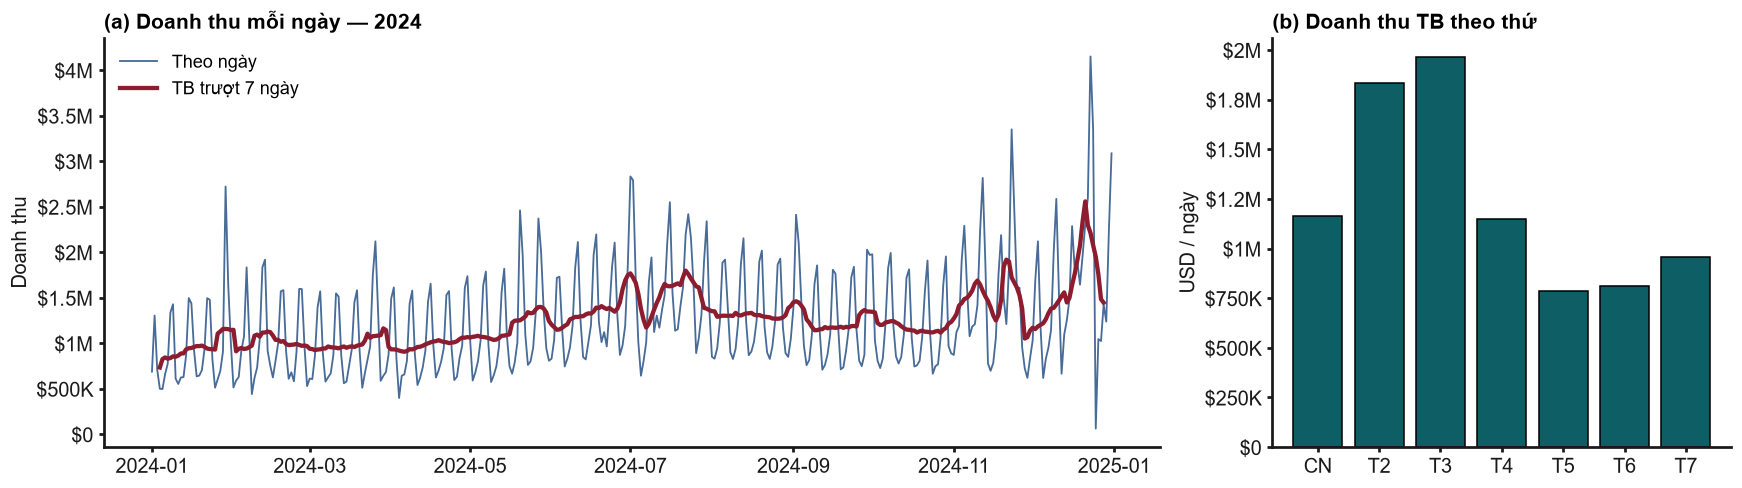

In [14]:
wd = dl.query("sales_weekday")
fig, axes = viz.new_figure(1, 2, figsize=(16, 4.6), gridspec_kw={"width_ratios": [2.3, 1]})
axes[0].plot(daily["SalesDate"], daily["dollars"], color=PALETTE["blue"], lw=1.2, alpha=0.75, label="Theo ngày")
axes[0].plot(daily["SalesDate"], daily["dollars"].rolling(7, center=True).mean(), color=PALETTE["wine"],
             lw=2.8, label="TB trượt 7 ngày")
axes[0].legend()
viz.fmt_axis(axes[0], y="money")
viz.label(axes[0], "(a) Doanh thu mỗi ngày — 2024", None, "Doanh thu")
viz.bar(axes[1], [pp.WEEKDAY_VI[i] for i in wd["Weekday"]], {"TB/ngày": wd["avg_dollars"]},
        colors=[PALETTE["teal"]])
viz.fmt_axis(axes[1], y="money")
viz.label(axes[1], "(b) Doanh thu TB theo thứ", None, "USD / ngày")
viz.save_figure(fig, "02_sales_time_distribution")
plt.show()

**Biểu đồ 2.8 — Doanh thu theo tháng, tách 2 nhóm sản phẩm** (cột chồng).

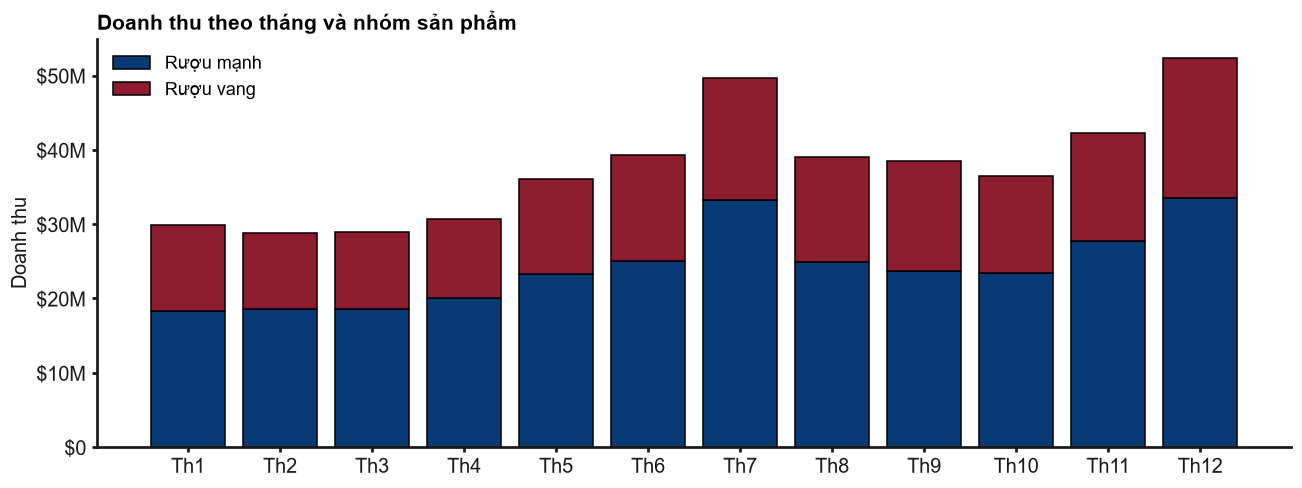

ClassName,Rượu mạnh,Rượu vang,total,wine_share_pct
Month,,,,
2024-01,"18,289,796.35","11,564,231.57","29,854,027.92",38.74
2024-02,"18,580,057.17","10,296,550.06","28,876,607.23",35.66
2024-03,"18,537,549.75","10,450,862.19","28,988,411.94",36.05
2024-04,"20,091,246.48","10,632,488.15","30,723,734.63",34.61
2024-05,"23,255,750.01","12,785,460.51","36,041,210.52",35.47
2024-06,"25,025,087.11","14,265,614.35","39,290,701.46",36.31
2024-07,"33,285,356.97","16,411,109.88","49,696,466.85",33.02
2024-08,"24,905,360.26","14,150,805.77","39,056,166.03",36.23
2024-09,"23,654,943.68","14,822,595.15","38,477,538.83",38.52


In [15]:
m = dl.query("sales_monthly").pivot(index="Month", columns="ClassName", values="dollars")
fig, (ax,) = viz.new_figure(figsize=(12, 4.6))
bottom = np.zeros(len(m))
for c in m.columns:
    ax.bar(pp.month_label(pd.Series(m.index)), m[c], bottom=bottom, color=CLASS_COLORS[c],
           edgecolor="black", linewidth=1, label=c)
    bottom += m[c].to_numpy()
ax.legend()
viz.fmt_axis(ax, y="money")
viz.label(ax, "Doanh thu theo tháng và nhóm sản phẩm", None, "Doanh thu")
viz.save_figure(fig, "02_sales_monthly_class")
plt.show()
(m.assign(total=m.sum(axis=1), wine_share_pct=lambda d: d["Rượu vang"] / d["total"] * 100))

## 9. Tồn kho đầu kỳ vs cuối kỳ

**Biểu đồ 2.9 — Phân phối số lượng tồn (onHand) mỗi mặt hàng** ở 01/01 và 31/12
(chỉ mặt hàng có tồn > 0), cùng biến động tồn kho cấp mặt hàng.

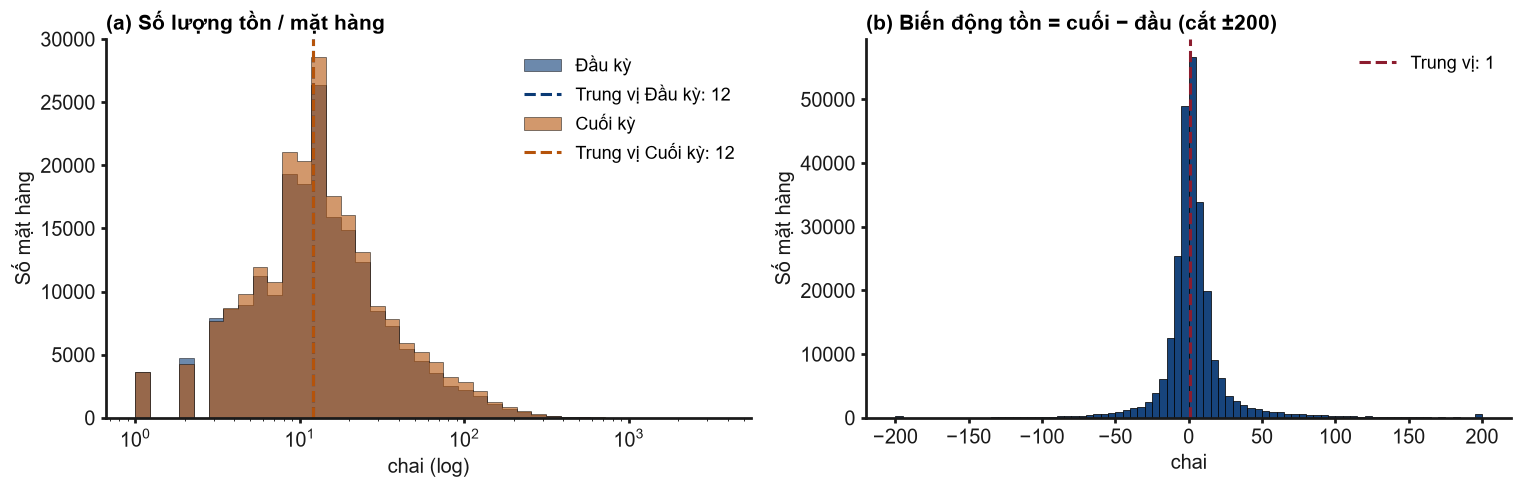

,status,Classification,n_items,begin_units,end_units,begin_value,end_value
0,Chỉ có cuối kỳ (mới),1,21335,0,466489,0.00,"6,420,524.81"
1,Chỉ có cuối kỳ (mới),2,28178,0,428584,0.00,"8,069,503.10"
2,Chỉ có đầu kỳ (ngừng),1,17593,270212,0,"3,649,627.68",0.00
3,Chỉ có đầu kỳ (ngừng),2,13960,197035,0,"3,682,874.70",0.00
4,Có cả hai kỳ,1,86925,2028508,2217387,"34,920,173.73","39,335,002.58"
5,Có cả hai kỳ,2,88051,1723520,1773316,"25,801,104.06","25,879,820.64"


In [16]:
inv = dl.query("inventory_items")
fig, axes = viz.new_figure(1, 2, figsize=(14, 4.6))
viz.hist(axes[0], {"Đầu kỳ": pp.positive(inv["begin_onhand"]), "Cuối kỳ": pp.positive(inv["end_onhand"])},
         log_x=True, bins=40, colors=[PALETTE["blue"], PALETTE["orange"]], alpha=0.6)
viz.label(axes[0], "(a) Số lượng tồn / mặt hàng", "chai (log)", "Số mặt hàng")
viz.hist(axes[1], inv["delta_onhand"].clip(-200, 200), bins=80, color=None)
viz.label(axes[1], "(b) Biến động tồn = cuối − đầu (cắt ±200)", "chai", "Số mặt hàng")
viz.save_figure(fig, "02_inventory_distribution")
plt.show()
dl.query("inventory_status")

## 10. Nhận xét

1. **Mọi biến tiền/số lượng đều lệch phải mạnh** (skew ≫ 1): giao dịch bán điển hình chỉ 1 chai
   (trung vị), giá ~13 USD, doanh thu/dòng ~19 USD, nhưng đuôi kéo đến hàng nghìn USD → luôn vẽ/so
   sánh trên thang log và dùng trung vị thay cho trung bình. Ngoại lai nên đếm theo IQR trên log10.
2. **Hai nhóm sản phẩm khác nhau rõ:** rượu vang chiếm ~70 % số sản phẩm nhưng chỉ ~36 % doanh thu;
   giá trung vị thấp hơn rượu mạnh, nhưng **biên đơn vị cao hơn** (~34 % so với ~26 %). Thuế tiêu thụ
   trên mỗi lít của rượu mạnh cao gấp ~7 lần rượu vang (~1,05 so với ~0,15 USD/lít) → `ExciseTax` gần như
   là hàm tất định của dung tích × nhóm.
3. **Đỉnh ở giá ~1 USD** (panel 2.1a, 2.3a) là các chai mini 50 mL của rượu mạnh — một phân khúc riêng.
4. **Chuỗi cung ứng rất đều:** 5 000/5 543 PO được giao thành nhiều đợt. Lead time PO (đặt → **nhận đủ**)
   3–14 ngày, TB **~9,9 ngày** (khớp `data_dictionary.md`); nhận lô đầu TB ~6 ngày; trung bình theo dòng mua
   ~7,7 ngày. Thời gian thanh toán 23–48 ngày, TB ~35,5 ngày, phân phối gần đối xứng. Phí vận chuyển ~0,5 %
   giá trị hóa đơn ở hầu hết PO (trung vị 0,50 %); chỉ 84 PO (~1,5 %) vượt 1 %, cao nhất ~11,5 % — ngoại lai cần kiểm tra.
5. **Hiệu quả sản phẩm phân hóa:** biên gộp trung vị ~31 %, nhưng ~19 % cặp NCC × sản phẩm lỗ gộp và 178 sản phẩm
   không bán được; vòng quay tập trung quanh 1 (bán ≈ lượng mua) với đuôi trái dài (hàng chậm).
6. **Mùa vụ rõ:** doanh thu tăng từ ~29 triệu USD/tháng (Q1) lên đỉnh **tháng 7 (~50 triệu)** và **tháng 12
   (~52 triệu)**. Theo thứ trong tuần, Thứ 2–3 cao nhất, Thứ 5–6 thấp nhất — mẫu hình bất thường so với
   bán lẻ thực tế, có thể do dữ liệu mô phỏng.
7. **Giá trị tồn kho (tính theo giá bán lẻ) tăng ~17 %** (68,1 → 79,7 triệu USD); ~31 nghìn mặt hàng biến mất và ~49 nghìn mặt hàng mới xuất
   hiện so với đầu kỳ → danh mục tại cửa hàng thay đổi đáng kể trong năm.